# Time Series Forecasting Example

Monthly airline passengers 1949 to 1960. Same workflow works for store sales or revenue.

In [3]:
# import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [4]:
# load data and build a monthly date index
df = sns.load_dataset('flights')
df['date'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str), format='%Y-%b')
s = df.set_index('date')['passengers'].asfreq('MS')
s.head()

date
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: passengers, dtype: int64

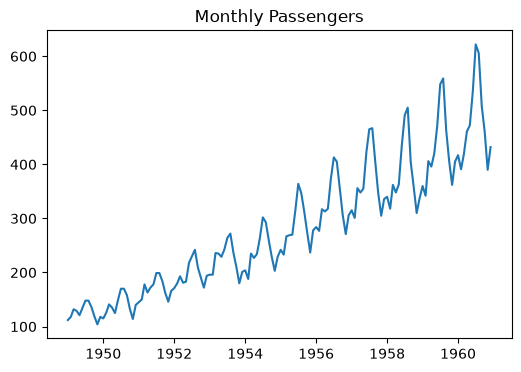

In [5]:
# plot the series
plt.figure(figsize=(6, 4))
plt.plot(s)
plt.title('Monthly Passengers')
plt.show()

## Decomposition

Splits the series into trend, seasonality and leftover noise.

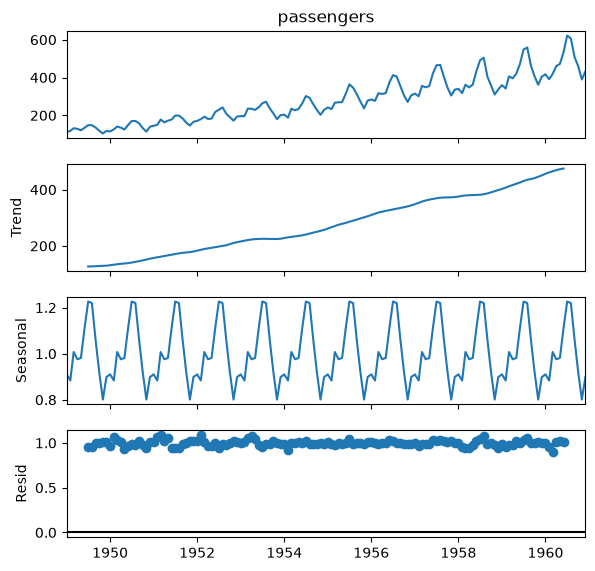

In [6]:
# multiplicative because seasonal swings grow with the trend
dec = seasonal_decompose(s, model='multiplicative')
fig = dec.plot()
fig.set_size_inches(6, 6)
plt.show()

## Train / test split

Last 24 months are held back to check the forecasts.

In [7]:
train = s[:-24]
test = s[-24:]
len(train), len(test)

(120, 24)

## Models

In [8]:
# 1. seasonal naive: same month last year
naive = train[-12:].values
naive = pd.Series(np.tile(naive, 2), index=test.index)

In [9]:
# 2. Holt-Winters exponential smoothing
hw = ExponentialSmoothing(train, trend='add', seasonal='mul', seasonal_periods=12).fit()
hw_fc = hw.forecast(24)

In [10]:
# 3. SARIMA on log values (log makes the seasonal swings even)
sarima = SARIMAX(np.log(train), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
sarima_fc = np.exp(sarima.forecast(24))

## Compare

MAPE = average error in percent, lower is better.

In [11]:
def mape(actual, forecast):
    return (abs(actual - forecast) / actual).mean() * 100

pd.Series({
    'Seasonal naive': mape(test, naive),
    'Holt-Winters': mape(test, hw_fc),
    'SARIMA': mape(test, sarima_fc),
}).round(1).rename('MAPE %')

Seasonal naive    15.5
Holt-Winters       6.4
SARIMA             7.8
Name: MAPE %, dtype: float64

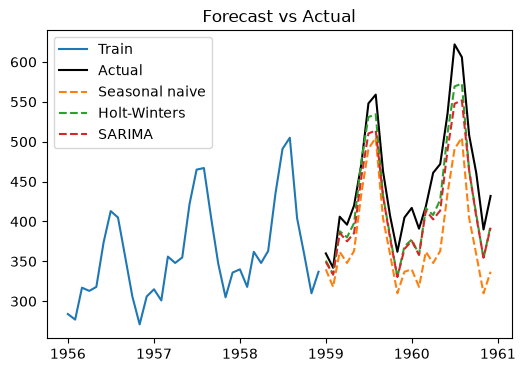

In [12]:
# plot forecasts vs actual
plt.figure(figsize=(6, 4))
plt.plot(train[-36:], label='Train')
plt.plot(test, label='Actual', color='black')
plt.plot(naive, label='Seasonal naive', linestyle='--')
plt.plot(hw_fc, label='Holt-Winters', linestyle='--')
plt.plot(sarima_fc, label='SARIMA', linestyle='--')
plt.title('Forecast vs Actual')
plt.legend()
plt.show()

## Forecast the future

Refit SARIMA on all data and forecast the next 12 months. Holt-Winters scored slightly better here, but SARIMA gives a confidence interval out of the box.

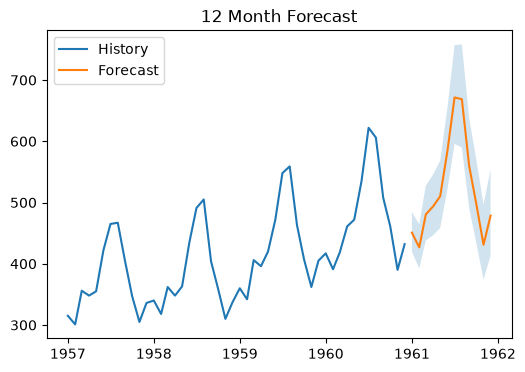

In [13]:
final = SARIMAX(np.log(s), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
pred = final.get_forecast(12)
fc = np.exp(pred.predicted_mean)
ci = np.exp(pred.conf_int())

plt.figure(figsize=(6, 4))
plt.plot(s[-48:], label='History')
plt.plot(fc, label='Forecast')
plt.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.2)
plt.title('12 Month Forecast')
plt.legend()
plt.show()